## Debuging and Monitoring
### LangSmith
### Langgraph Studio

<Code> langgraph dev

In [14]:
from typing import Annotated, TypedDict
from dotenv import load_dotenv

from langgraph.graph import add_messages, StateGraph, MessagesState, START, END
from langchain_core.messages import AnyMessage, HumanMessage
from langgraph.graph.message import add_messages

from langchain_groq import ChatGroq

from langchain.tools import tool
from langchain_community.tools import WikipediaQueryRun, DuckDuckGoSearchRun
from langchain_community.utilities import WikipediaAPIWrapper

from langgraph.checkpoint.memory import MemorySaver
from uuid import uuid4
import os

load_dotenv()

True

In [15]:
wiki_wrapper = WikipediaAPIWrapper(top_k_results=2 ,doc_content_chars_max=500)
wiki = WikipediaQueryRun(api_wrapper=wiki_wrapper, description="Find Information from Wikipedia Pages")

In [16]:
duck_duck_go = DuckDuckGoSearchRun(
    name="web_search_on_Duck_Duck_Go",
    description="Search the web for current events, recent news, live scores, and real-time information."
    )

In [17]:
@tool
def add(a: int, b: int) -> int:
    """Add Two Numbers"""
    return a + b

In [18]:
tools = [add]

In [19]:
os.environ['GROQ_API_KEY'] = os.getenv("GROQ_API_KEY")
os.environ['LANGSMITH_API_KEY'] = os.getenv("LANGSMITH_API_KEY")
os.environ['LANGSMITH_TRACING'] = 'true'
os.environ['LANGSMITH_PROJECT'] = 'Krish Naik Debug 1'


In [20]:
model = ChatGroq(model="qwen/qwen3.8-27b", temperature=0.2)

lllm_with_tools = model.bind_tools(tools)

In [21]:
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [22]:
# def llm_call(state: State) -> State:
#     return {"messages": [model.invoke(state['messages'])]}

def tool_calling_llm(state: State) -> State:
    return {'messages': [lllm_with_tools.invoke(state['messages'])  ]}

In [23]:
from langgraph.prebuilt import ToolNode, tools_condition

In [24]:
short_term_memory = MemorySaver()

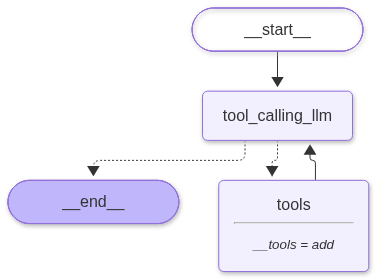

In [25]:
graph = StateGraph(State)

graph.add_node('tool_calling_llm', tool_calling_llm)
graph.add_node('tools', ToolNode(tools))

graph.set_entry_point('tool_calling_llm')
graph.add_conditional_edges('tool_calling_llm', tools_condition)
graph.add_edge('tools', 'tool_calling_llm')

build = graph.compile(checkpointer=short_term_memory)

build

In [26]:
config = {'configurable': {'thread_id': 1}}

message = build.invoke({'messages': [HumanMessage('What is Statistics')]}, config=config)

In [27]:
for m in message['messages']:
    m.pretty_print()

================================ Human Message =================================

What is Statistics
================================== Ai Message ==================================

Statistics is the science of collecting, organizing, analyzing, interpreting, and presenting data. It provides a framework for making sense of uncertainty and variability in the world.

### Key Components of Statistics:

1. **Descriptive Statistics**:  
   - Summarizes and describes the main features of a dataset.
   - Includes measures like mean, median, mode, standard deviation, and visual tools like histograms and bar charts.

2. **Inferential Statistics**:  
   - Uses sample data to make inferences or predictions about a larger population.
   - Involves hypothesis testing, confidence intervals, and regression analysis.

3. **Probability**:  
   - The mathematical foundation of statistics, dealing with the likelihood of events occurring.

### Applications:
- **Science & Research**: Designing experiments